In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data_jobs.csv')

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [4]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])

df_DA_US['salary_year_avg'].sample(10)

590904    100000.0
386329     67500.0
183843    150000.0
988        62623.0
346175     97500.0
301220     50325.0
690145     35000.0
313180    120000.0
743645     92500.0
211169     61250.0
Name: salary_year_avg, dtype: float64

<Axes: >

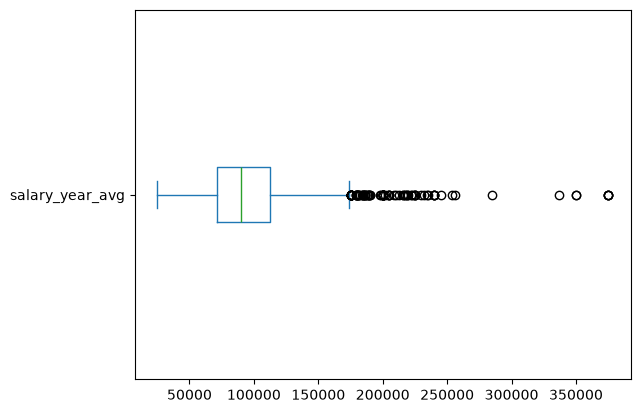

In [6]:
df_DA_US['salary_year_avg'].plot(kind='box', vert=False)

C:\Users\Youssef.Louca\AppData\Local\Temp\ipykernel_1992\1551041375.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list, tick_labels=job_titles, vert=False)


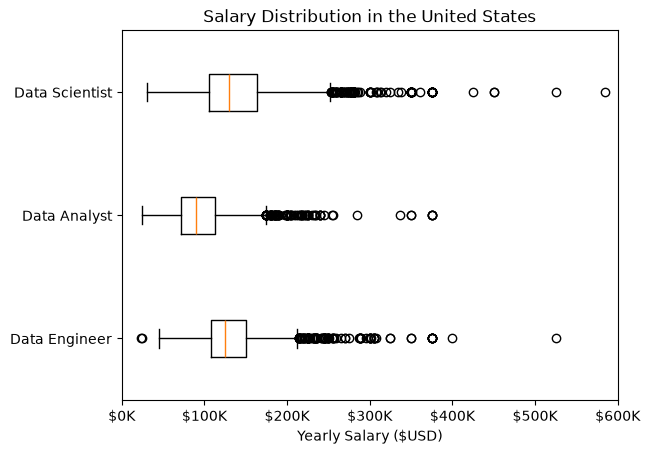

In [ ]:
job_titles = ['Data Engineer', 'Data Analyst', 'Data Scientist']
df_US = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'United States')].copy()

df_US = df_US.dropna(subset=['salary_year_avg'])

job_list = [df_US[df_US['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

plt.boxplot(job_list, tick_labels=job_titles, vert=False)
plt.title('Salary Distribution in the United States')
plt.xlabel('Yearly Salary ($USD)')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.xlim(0, 600000)
plt.show()

C:\Users\Youssef.Louca\AppData\Local\Temp\ipykernel_1992\2381964619.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_DS_salary['salary_hour_avg'], vert=False)


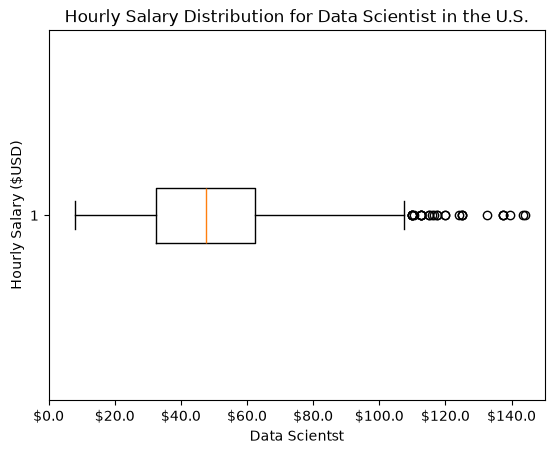

In [41]:
df_DS = df[df['job_title_short'] == 'Data Scientist'].copy()
df_DS_salary = df_DS.dropna(subset=['salary_hour_avg'])
plt.boxplot(df_DS_salary['salary_hour_avg'], vert=False)
plt.xlabel('Data Scientst')
plt.ylabel('Hourly Salary ($USD)')
plt.title('Hourly Salary Distribution for Data Scientist in the U.S.')
plt.xlim(0, 150)
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, __: f'${x}'))

C:\Users\Youssef.Louca\AppData\Local\Temp\ipykernel_1992\1180737985.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(country_list, tick_labels=countries, vert=False)


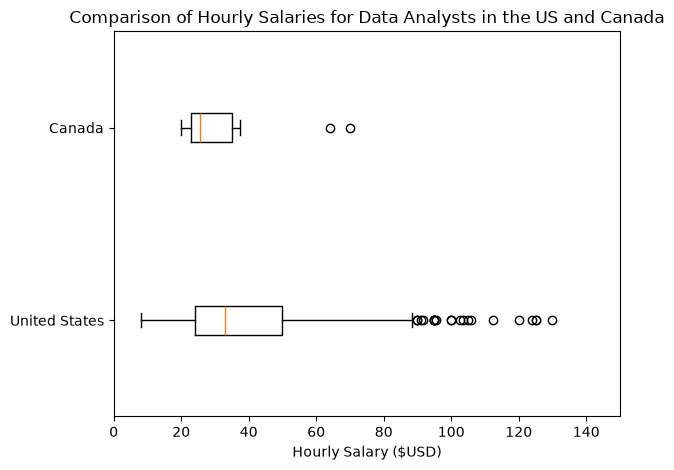

In [60]:
countries = ['United States', 'Canada']
df_DA = df[(df['job_title_short'] == 'Data Analyst')].copy()
df_DA = df_DA.dropna(subset=['salary_hour_avg'])

country_list = [df_DA[df_DA['job_country'] == country]['salary_hour_avg'] for country in countries]

plt.boxplot(country_list, tick_labels=countries, vert=False)
plt.xlim(0, 150)
plt.xlabel('Hourly Salary ($USD)')
plt.title('Comparison of Hourly Salaries for Data Analysts in the US and Canada')
plt.tight_layout()
plt.show()

C:\Users\Youssef.Louca\AppData\Local\Temp\ipykernel_1992\3396575105.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(titles_list, tick_labels=job_titles, vert=False)


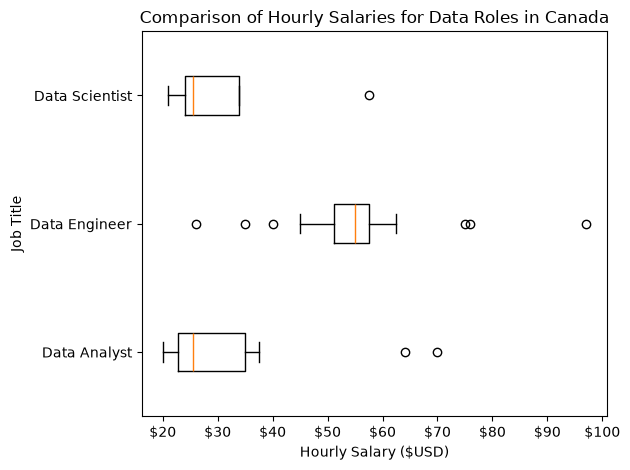

In [70]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']
df_CA = df[df['job_country'] == 'Canada'].dropna(subset=['salary_hour_avg']).copy()

titles_list = [df_CA[df_CA['job_title_short'] == job_title]['salary_hour_avg'] for job_title in job_titles]

plt.boxplot(titles_list, tick_labels=job_titles, vert=False)

plt.ylabel('Job Title')
plt.xlabel('Hourly Salary ($USD)')
plt.title('Comparison of Hourly Salaries for Data Roles in Canada')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, __: f'${x:,.0f}'))

plt.tight_layout()
plt.show()